# DreamPoly

Лексика, эмоции и темы в DreamBank. Сначала возрастные серии Izzy, затем студенческие коллекции мужчин и женщин 1997–1998.

Источник: [DreamBank](https://dreambank.net/), Adam Schneider и G. William Domhoff. Снимок [5 января 2026](https://zenodo.org/records/18159468), CC BY-NC-SA 4.0.

## 1. Библиотеки и папки

In [1]:
# %pip install -r requirements.txt

from pathlib import Path
from collections import Counter
import hashlib
import json
import re
import tarfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from nrclex import NRCLex
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF
from nltk.stem import SnowballStemmer
from scipy.stats import mannwhitneyu
from IPython.display import display, Markdown

ROOT = Path.cwd()
RAW = ROOT / 'data' / 'raw'
HTML = RAW / 'html'
TABLES = ROOT / 'data' / 'processed'
RESULTS = ROOT / 'data' / 'results'
FIGURES = ROOT / 'figures'
for folder in [RAW, HTML, TABLES, RESULTS, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)
plt.rcParams['font.family'] = 'DejaVu Sans'
print('Рабочая папка:', ROOT)

Рабочая папка: c:\Users\user\Downloads\dreambank-analysis


## 2. Архив

In [2]:
ARCHIVE = RAW / 'dreambank.tar.xz'
EXPECTED_MD5 = 'eb83bcb0828f9c8c248a5052b2ffc798'
if not ARCHIVE.exists():
    request = urllib.request.Request(
        'https://zenodo.org/api/records/18159468',
        headers={'User-Agent': 'DreamPoly educational project'})
    with urllib.request.urlopen(request, timeout=60) as response:
        record = json.load(response)
    file_info = next(f for f in record['files'] if f['key'] == ARCHIVE.name)
    urllib.request.urlretrieve(file_info['links']['self'], ARCHIVE)
assert hashlib.md5(ARCHIVE.read_bytes()).hexdigest() == EXPECTED_MD5

with tarfile.open(ARCHIVE, 'r:xz') as archive:
    for member in archive.getmembers():
        name = Path(member.name)
        if member.isfile() and not name.is_absolute() and '..' not in name.parts:
            target = (HTML / name).resolve()
            if HTML.resolve() in target.parents:
                target.parent.mkdir(parents=True, exist_ok=True)
                target.write_bytes(archive.extractfile(member).read())
print('HTML-файлов:', len(list(HTML.rglob('*.html'))))

HTML-файлов: 289


## 3. Парсинг HTML

В `info.html` метаданные серии, в `dreams.html` тексты. Запись начинается с `#номера` и заканчивается числом слов. Возраст и даты в заголовке остаются как в источнике.

In [3]:
def clean(text):
    return re.sub(r'\s+', ' ', text).strip()

def read_series(folder):
    soup = BeautifulSoup((folder / 'info.html').read_bytes(), 'html.parser', from_encoding='windows-1252')
    labels = {'Dream series:': 'series_title', 'Number of dreams:': 'reported_count',
              'Year:': 'series_years_raw', 'Sex of the dreamer(s):': 'dreamer_sex_raw'}
    row = {'series_id': folder.name, 'language': 'de' if folder.name.endswith('.de') else 'en'}
    for bold in soup.find_all('b'):
        label = clean(bold.get_text(' ', strip=True))
        if label in labels:
            pieces = []
            for sibling in bold.next_siblings:
                if getattr(sibling, 'name', None) == 'br':
                    break
                pieces.append(sibling.get_text(' ', strip=True)
                              if getattr(sibling, 'name', None) else str(sibling))
            row[labels[label]] = clean(' '.join(pieces))
    row['reported_count'] = int(row['reported_count'].replace(',', ''))
    return row

def read_dreams(folder, series):
    soup = BeautifulSoup((folder / 'dreams.html').read_bytes(), 'html.parser', from_encoding='windows-1252')
    rows = []
    for span in soup.find_all('span'):
        header_parts = []
        for child in span.contents:
            if getattr(child, 'name', None) == 'br':
                break
            header_parts.append(child.get_text(' ', strip=True)
                                if getattr(child, 'name', None) else str(child))
        header = clean(' '.join(header_parts))
        if not header.startswith('#'):
            continue
        number, metadata = re.match(r'^#(\S+)(?:\s+\((.*)\))?$', header).groups()
        body = clean(span.get_text(' ', strip=True))[len(header):].strip()
        word_count = re.search(r'\(([\d,]+)\s+words?\)\s*$', body, re.I)
        text = clean(body[:word_count.start()])
        rows.append({
            'dream_id': f"{folder.name}:{number}", 'series_id': folder.name,
            'dream_number_raw': number, 'header_metadata_raw': metadata or '',
            'text': text, 'word_count_reported': int(word_count[1].replace(',', '')),
            'language': series['language'], 'dreamer_sex_raw': series['dreamer_sex_raw'],
            'series_years_raw': series['series_years_raw'],
            'source_file': (folder / 'dreams.html').relative_to(ROOT).as_posix()})
    return rows

In [4]:
series_rows, dream_rows = [], []
for folder in sorted(HTML.iterdir()):
    if folder.is_dir() and (folder / 'info.html').exists():
        series = read_series(folder)
        records = read_dreams(folder, series)
        series['parsed_count'] = len(records)
        series_rows.append(series)
        dream_rows.extend(records)
series_df = pd.DataFrame(series_rows)
dreams = pd.DataFrame(dream_rows)
display(dreams[['dream_id', 'text', 'language']].head())
print(f'Серий: {len(series_df)}, записей: {len(dreams):,}')
print(f'Количество записей на английском: {len(dreams[dreams['language']=='en'])}')

,dream_id,text,language
0,alta:1,"The one at the Meads's house, where it's bigge...",en
1,alta:2,I'm at a family reunion in a large fine house ...,en
2,alta:3,I watch a plane fly past and shortly realize i...,en
3,alta:4,Me pulling the green leaves and berries off so...,en
4,alta:5,I'm in a room that reminds me of (but definite...,en


Серий: 96, записей: 45,058
Количество записей на английском: 38128


## 4. Проверки

Пустые тексты и повторы идентификаторов. Сравнения по возрасту идут по сериям Izzy, не по таблице без дублей.

In [5]:
assert dreams['text'].str.len().gt(0).all(), 'Есть пустой текст'
assert dreams['dream_id'].is_unique, 'Повторился идентификатор'
unique_dreams = dreams.drop_duplicates('text').copy()
for name, table in [('series_simple', series_df), ('dreams_simple', dreams),
                    ('dreams_unique_simple', unique_dreams)]:
    table.to_csv(TABLES / f'{name}.csv', index=False, encoding='utf-8-sig')
    table.to_parquet(TABLES / f'{name}.parquet', index=False)
display(series_df.loc[series_df['reported_count'] != series_df['parsed_count'],
                      ['series_id', 'reported_count', 'parsed_count']])
print('Уникальных точных текстов:', len(unique_dreams))

,series_id,reported_count,parsed_count
3,b,3116,3114
17,college-f,160,159
50,kenneth,2022,2021
91,vonuslar.de,6100,6094


Уникальных точных текстов: 34838


В снимке 45 058 записей из 96 серий, 34 838 уникальных точных текстов. В четырёх сериях заявленное число не совпадает с числом записей.

## 5. Izzy

Один автор, разные возрастные серии. Возраст не отделён от эпохи и длины записей. Частоты NRC — на 1000 токенов сна.

In [6]:
AGE_GROUPS = {'izzy12': '12', 'izzy13': '13', 'izzy14': '14', 'izzy15': '15',
              'izzy16': '16', 'izzy17': '17', 'izzy18_21': '18–21', 'izzy22_25': '22–25'}
AGES = list(AGE_GROUPS.values())
izzy = dreams[dreams['series_id'].isin(AGE_GROUPS)].copy().reset_index(drop=True)
izzy['age_group'] = izzy['series_id'].map(AGE_GROUPS)
izzy['age_group'] = pd.Categorical(izzy['age_group'], categories=AGES, ordered=True)
display(izzy.groupby('age_group', observed=True).size().rename('Снов').to_frame())

EMOTIONS = ['anger', 'fear', 'anticipation', 'trust', 'surprise', 'sadness', 'disgust', 'joy']
vader, nrc = SentimentIntensityAnalyzer(), NRCLex()

def tokens(text):
    return re.findall(r"[A-Za-z]+(?:['’][A-Za-z]+)?", text.lower())

def features(text):
    words = tokens(text)
    nrc.load_token_list(words)
    result = {'token_count': len(words), 'vader': vader.polarity_scores(text)['compound']}
    for emotion in EMOTIONS:
        result[emotion] = nrc.raw_emotion_scores.get(emotion, 0) * 1000 / max(len(words), 1)
    result['mattr_50'] = (np.mean([len(set(words[i:i+50])) / 50
                                for i in range(len(words)-49)]) if len(words) >= 50 else np.nan)
    return result

izzy = pd.concat([izzy, pd.DataFrame([features(t) for t in izzy['text']])], axis=1)
age_means = izzy.groupby('age_group', observed=True)[
    ['token_count', 'mattr_50', 'vader'] + EMOTIONS].mean()
izzy.to_parquet(RESULTS / 'izzy_per_dream.parquet', index=False)
age_means.to_csv(RESULTS / 'izzy_by_age.csv', encoding='utf-8-sig')

,Снов
age_group,
12,52
13,167
14,249
15,539
16,845
17,741
18–21,1359
22–25,377


## 6. Эмоции и тональность

Частота слов NRC и оценка VADER от −1 до +1.

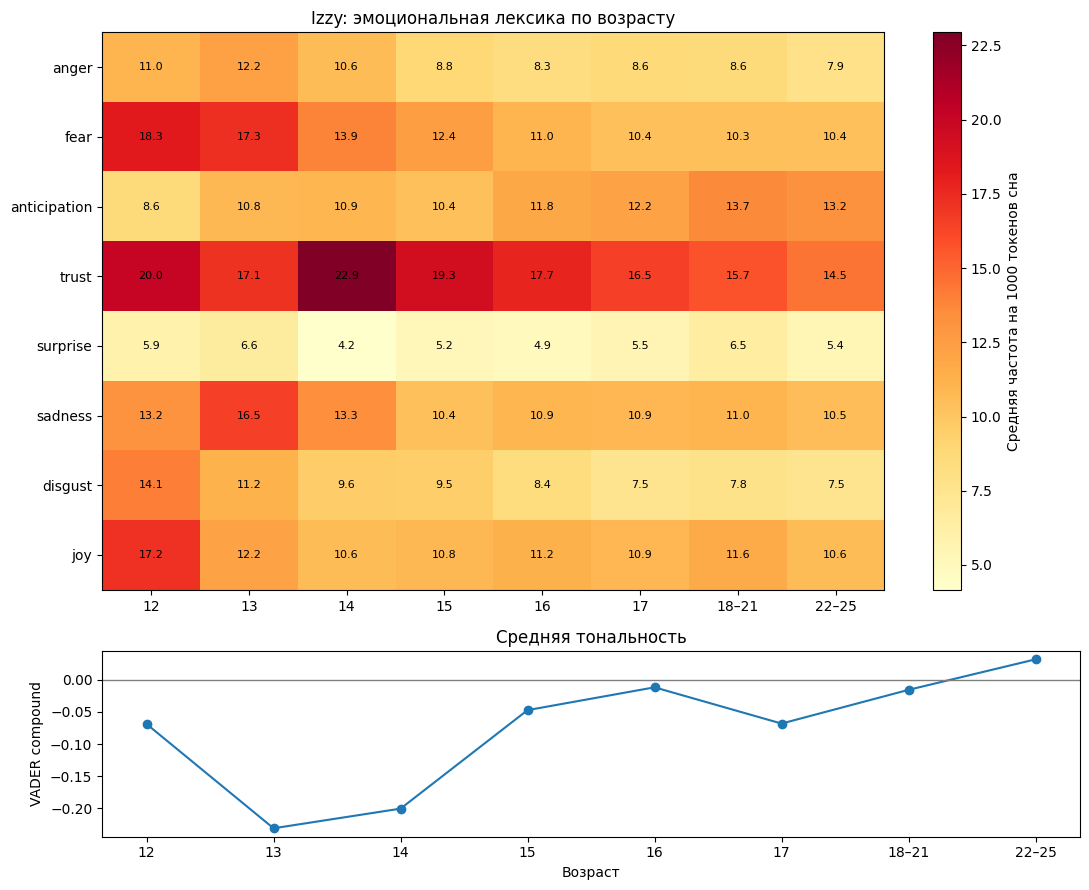

**Вывод:** частота лексики страха меняется с 18.3 до 10.4 на 1000 токенов. Тональность поздних записей в среднем выше ранних. Это наблюдение по одному дневнику, не доказательство влияния возраста.

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(11, 9), gridspec_kw={'height_ratios': [3, 1]})
heat = age_means[EMOTIONS].T.to_numpy()
image = axes[0].imshow(heat, aspect='auto', cmap='YlOrRd')
axes[0].set_xticks(range(len(AGES)), AGES)
axes[0].set_yticks(range(len(EMOTIONS)), EMOTIONS)
axes[0].set_title('Izzy: эмоциональная лексика по возрасту')
for row in range(len(EMOTIONS)):
    for col in range(len(AGES)):
        axes[0].text(col, row, f'{heat[row, col]:.1f}', ha='center', va='center', fontsize=8)
fig.colorbar(image, ax=axes[0], label='Средняя частота на 1000 токенов сна')
axes[1].plot(AGES, age_means['vader'], marker='o')
axes[1].axhline(0, color='gray', linewidth=1)
axes[1].set(xlabel='Возраст', ylabel='VADER compound', title='Средняя тональность')
fig.tight_layout()
fig.savefig(FIGURES / '01_emotions_by_age.png', dpi=160, bbox_inches='tight')
plt.show()
display(Markdown(f"**Вывод:** частота лексики страха меняется с {age_means['fear'].iloc[0]:.1f} "
                 f"до {age_means['fear'].iloc[-1]:.1f} на 1000 токенов. "
                 'Тональность поздних записей в среднем выше ранних. '
                 'Это наблюдение по одному дневнику, не доказательство влияния возраста.'))

## 7. Длина и словарь

MATTR-50 — доля разных слов в окнах по 50 токенов. Тексты короче 50 слов в метрику не входят.

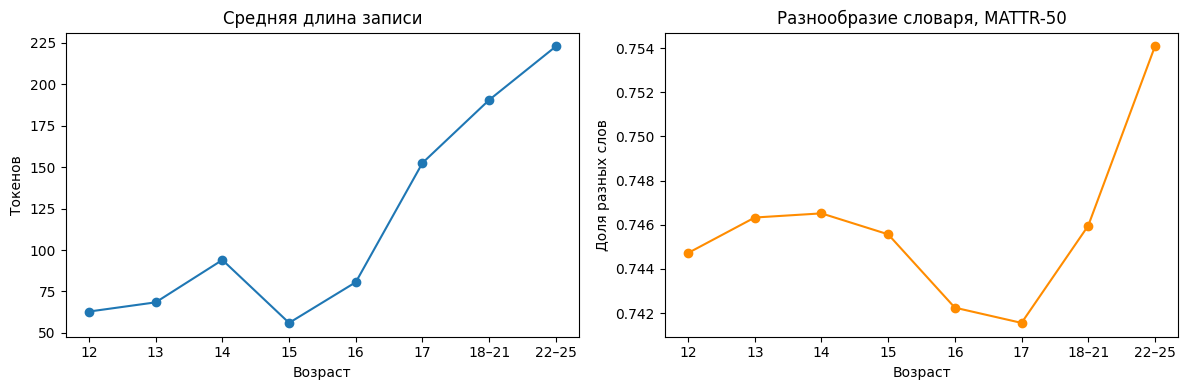

age_group
12         27
13         95
14        185
15        235
16        483
17        589
18–21    1222
22–25     351
Name: Записей ≥ 50 токенов, dtype: int64

**Вывод:** средняя длина возрастает с 63 до 223 токенов. Изменение MATTR значительно скромнее; длина и стиль рассказа могут объяснять часть возрастных различий.

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(AGES, age_means['token_count'], marker='o')
axes[0].set(title='Средняя длина записи', xlabel='Возраст', ylabel='Токенов')
axes[1].plot(AGES, age_means['mattr_50'], marker='o', color='darkorange')
axes[1].set(title='Разнообразие словаря, MATTR-50', xlabel='Возраст', ylabel='Доля разных слов')
fig.tight_layout()
fig.savefig(FIGURES / '02_length_vocabulary.png', dpi=160, bbox_inches='tight')
plt.show()
display(izzy.groupby('age_group', observed=True)['mattr_50'].count().rename('Записей ≥ 50 токенов'))
display(Markdown(f"**Вывод:** средняя длина возрастает с {age_means['token_count'].iloc[0]:.0f} "
                 f"до {age_means['token_count'].iloc[-1]:.0f} токенов. "
                 'Изменение MATTR значительно скромнее; длина и стиль рассказа '
                 'могут объяснять часть возрастных различий.'))

## 8. Темы

TF–IDF и NMF, восемь компонентов. Названия даны по ключевым словам. Веса нормированы по строке и не равны доле снов на тему.

In [9]:
vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(1, 2),
                            min_df=10, max_df=0.85, max_features=6000, sublinear_tf=True)
izzy_topics = izzy.sort_values(['series_id', 'dream_number_raw']).reset_index(drop=True)
matrix = vectorizer.fit_transform(izzy_topics['text'])
model = NMF(n_components=8, init='nndsvda', random_state=42, max_iter=700)
weights = model.fit_transform(matrix)
shares = weights / np.maximum(weights.sum(axis=1, keepdims=True), 1e-12)
terms = vectorizer.get_feature_names_out()
labels = ['Диалоги', 'Школа', 'Воспоминание', 'Семья и дом',
          'Фильмы', 'Люди и действия', 'Комнаты и здания', 'Повторяющиеся имена']
topic_terms = pd.DataFrame({'Компонент': labels,
                           'Ключевые слова': [', '.join(terms[c.argsort()[-12:][::-1]])
                                             for c in model.components_]})
display(topic_terms)
topic_terms.to_csv(RESULTS / 'topic_terms.csv', index=False, encoding='utf-8-sig')
topic_table = pd.DataFrame(shares, columns=labels)
topic_table['age_group'] = izzy_topics['age_group']
topic_by_age = topic_table.groupby('age_group', observed=True)[labels].mean()
topic_by_age.to_csv(RESULTS / 'topics_by_age.csv', encoding='utf-8-sig')

,Компонент,Ключевые слова
0,Диалоги,"said, like, didn, asked, know, saying, just, t..."
1,Школа,"calvin, school, dmitri, samantha, evelyn, elij..."
2,Воспоминание,"remember, don remember, don, dream, properly, ..."
3,Семья и дом,"ezra, mom, dad, home, car, mom ezra, dad ezra,..."
4,Фильмы,"watching, movie, watching movie, guy, tv, girl..."
5,Люди и действия,"guy, people, got, place, thing, girl, went, ca..."
6,Комнаты и здания,"room, house, door, bed, went, came, outside, r..."
7,Повторяющиеся имена,"eugene, darius, jeremiah, bradley, thinking, s..."


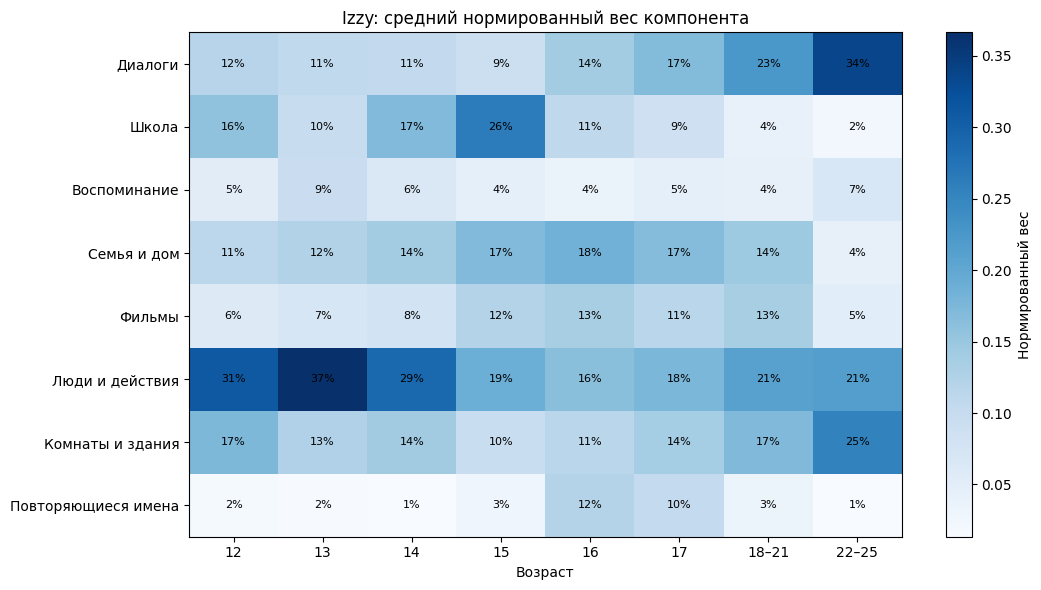

**Вывод:** сравниваем изменение словарных компонентов по возрасту. Снижение веса школы согласуется с переходом к другим жизненным периодам, но NMF может реагировать также на имена и стиль дневника. Названия проверяем по таблице ключевых слов выше.

In [10]:
fig, ax = plt.subplots(figsize=(11, 6))
heat = topic_by_age.T.to_numpy()
image = ax.imshow(heat, aspect='auto', cmap='Blues')
ax.set_xticks(range(len(AGES)), AGES)
ax.set_yticks(range(len(labels)), labels)
ax.set(xlabel='Возраст', title='Izzy: средний нормированный вес компонента')
for row in range(len(labels)):
    for col in range(len(AGES)):
        ax.text(col, row, f'{heat[row, col]:.0%}', ha='center', va='center', fontsize=8)
fig.colorbar(image, ax=ax, label='Нормированный вес')
fig.tight_layout()
fig.savefig(FIGURES / '03_topics_by_age.png', dpi=160, bbox_inches='tight')
plt.show()
display(Markdown('**Вывод:** сравниваем изменение словарных компонентов по возрасту. '
                 'Снижение веса школы согласуется с переходом к другим жизненным периодам, '
                 'но NMF может реагировать также на имена и стиль дневника. '
                 'Названия проверяем по таблице ключевых слов выше.'))

## 9. Пол

Серии `college-f` и `college-m`: студенты одного периода. Mann–Whitney по записям, поправка Benjamini–Hochberg.

In [11]:
GROUPS = {'college-f': 'Женщины', 'college-m': 'Мужчины'}
college = dreams[dreams['series_id'].isin(GROUPS)].copy().reset_index(drop=True)
college['group'] = college['series_id'].map(GROUPS)
college = pd.concat([college, pd.DataFrame([features(t) for t in college['text']])], axis=1)
display(college.groupby('group').size().rename('Число записей'))
metrics = ['token_count', 'mattr_50', 'vader'] + EMOTIONS
gender_means = college.groupby('group')[metrics].mean()
comparison = []
for metric in metrics:
    female = college.loc[college['group'] == 'Женщины', metric].dropna()
    male = college.loc[college['group'] == 'Мужчины', metric].dropna()
    test = mannwhitneyu(female, male, alternative='two-sided')
    comparison.append({'metric': metric, 'female_mean': female.mean(), 'male_mean': male.mean(),
                       'p': test.pvalue, 'cliffs_delta': 2*test.statistic/(len(female)*len(male))-1})
comparison = pd.DataFrame(comparison).sort_values('p').reset_index(drop=True)
adjusted = comparison['p'].to_numpy() * len(metrics) / np.arange(1, len(metrics)+1)
comparison['p_adjusted'] = np.minimum.accumulate(adjusted[::-1])[::-1].clip(0, 1)
display(comparison.round(4))
comparison.to_csv(RESULTS / 'gender_comparison.csv', index=False, encoding='utf-8-sig')
college.to_parquet(RESULTS / 'college_per_dream.parquet', index=False)

group
Женщины    159
Мужчины    160
Name: Число записей, dtype: int64

,metric,female_mean,male_mean,p,cliffs_delta,p_adjusted
0,token_count,139.5094,115.6375,0.0020,0.1997,0.0225
1,disgust,7.4394,5.9506,0.0212,0.1380,0.1164
2,anger,8.7234,10.2935,0.0979,-0.1018,0.3083
3,mattr_50,0.7478,0.7411,0.1121,0.1078,0.3083
4,sadness,14.7478,13.0583,0.4364,0.0496,0.7403
5,trust,21.7540,24.6478,0.4992,-0.0437,0.7403
6,vader,0.1848,0.2366,0.5740,-0.0364,0.7403
7,anticipation,18.6963,21.0587,0.6197,-0.0321,0.7403
8,fear,11.4798,13.2283,0.6396,-0.0294,0.7403
9,surprise,9.2941,11.1961,0.7037,-0.0239,0.7403


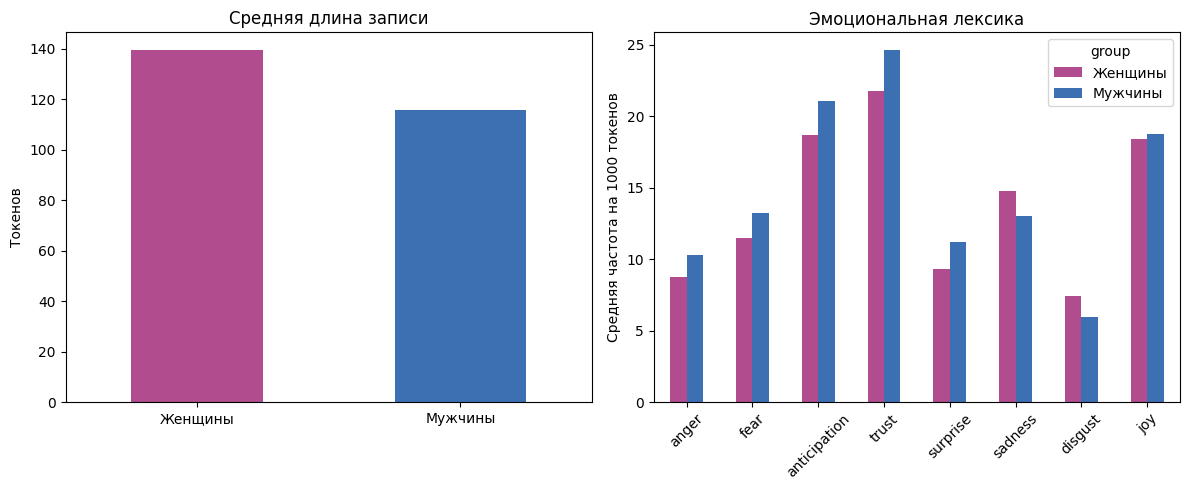

**Вывод:** средняя длина женских записей — 139.5, мужских — 115.6 токена. Различия эмоциональных оценок после поправки неубедительны. Результат относится к этим коллекциям, не ко всем людям.

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
gender_means['token_count'].reindex(['Женщины', 'Мужчины']).plot.bar(
    ax=axes[0], color=['#b14d8e', '#3d70b2'], rot=0)
axes[0].set(title='Средняя длина записи', ylabel='Токенов', xlabel='')
gender_means[EMOTIONS].T[['Женщины', 'Мужчины']].plot.bar(
    ax=axes[1], color=['#b14d8e', '#3d70b2'], rot=45)
axes[1].set(title='Эмоциональная лексика', ylabel='Средняя частота на 1000 токенов', xlabel='')
fig.tight_layout()
fig.savefig(FIGURES / '04_gender_metrics.png', dpi=160, bbox_inches='tight')
plt.show()
display(Markdown(f"**Вывод:** средняя длина женских записей — {gender_means.loc['Женщины', 'token_count']:.1f}, "
                 f"мужских — {gender_means.loc['Мужчины', 'token_count']:.1f} токена. "
                 'Различия эмоциональных оценок после поправки неубедительны. '
                 'Результат относится к этим коллекциям, не ко всем людям.'))

## 10. Слова по полу

Без служебных слов и слов о сне. Формы сведены стеммером Snowball. Частота на 10 000 содержательных токенов, сортировка по разности.

In [13]:
stop_words = set(ENGLISH_STOP_WORDS) | {
    'im', 'ive', 'id', 'dont', 'didnt', 'doesnt', 'wasnt', 'werent', 'isnt',
    'arent', 'couldnt', 'wouldnt', 'really', 'dream', 'dreamed', 'dreamt'}
stemmer = SnowballStemmer('english')
counts, forms, totals = {}, {}, {}
for group in ['Женщины', 'Мужчины']:
    counts[group], forms[group] = Counter(), {}
    for text in college.loc[college['group'] == group, 'text']:
        for word in tokens(text):
            if word in stop_words or len(word) < 3:
                continue
            stem = stemmer.stem(word)
            counts[group][stem] += 1
            forms[group].setdefault(stem, Counter())[word] += 1
    totals[group] = sum(counts[group].values())
rows = []
for stem in sorted(set(counts['Женщины']) | set(counts['Мужчины'])):
    f, m = counts['Женщины'][stem], counts['Мужчины'][stem]
    if f+m < 10:
        continue
    spellings = forms['Женщины'].get(stem, Counter()) + forms['Мужчины'].get(stem, Counter())
    rows.append({'word': spellings.most_common(1)[0][0], 'female_count': f, 'male_count': m,
                 'female': f*10000/totals['Женщины'], 'male': m*10000/totals['Мужчины']})
word_table = pd.DataFrame(rows)
word_table['shared'] = word_table[['female', 'male']].min(axis=1)
word_table['difference'] = word_table['female']-word_table['male']
word_table.to_csv(RESULTS / 'words_by_gender.csv', index=False, encoding='utf-8-sig')
common = word_table.nlargest(15, 'shared')
female_words = word_table.nlargest(12, 'difference')
male_words = word_table.nsmallest(12, 'difference')
display(common[['word', 'female_count', 'male_count', 'female', 'male']].round(2))

,word,female_count,male_count,female,male
109,friend,115,78,141.84,115.61
182,looked,94,75,115.93,111.16
175,like,94,68,115.93,100.79
238,remember,66,70,81.40,103.75
318,went,104,54,128.27,80.04
41,car,64,59,78.93,87.45
118,got,62,54,76.47,80.04
309,walked,69,47,85.10,69.66
155,just,62,46,76.47,68.18
321,woke,55,59,67.83,87.45


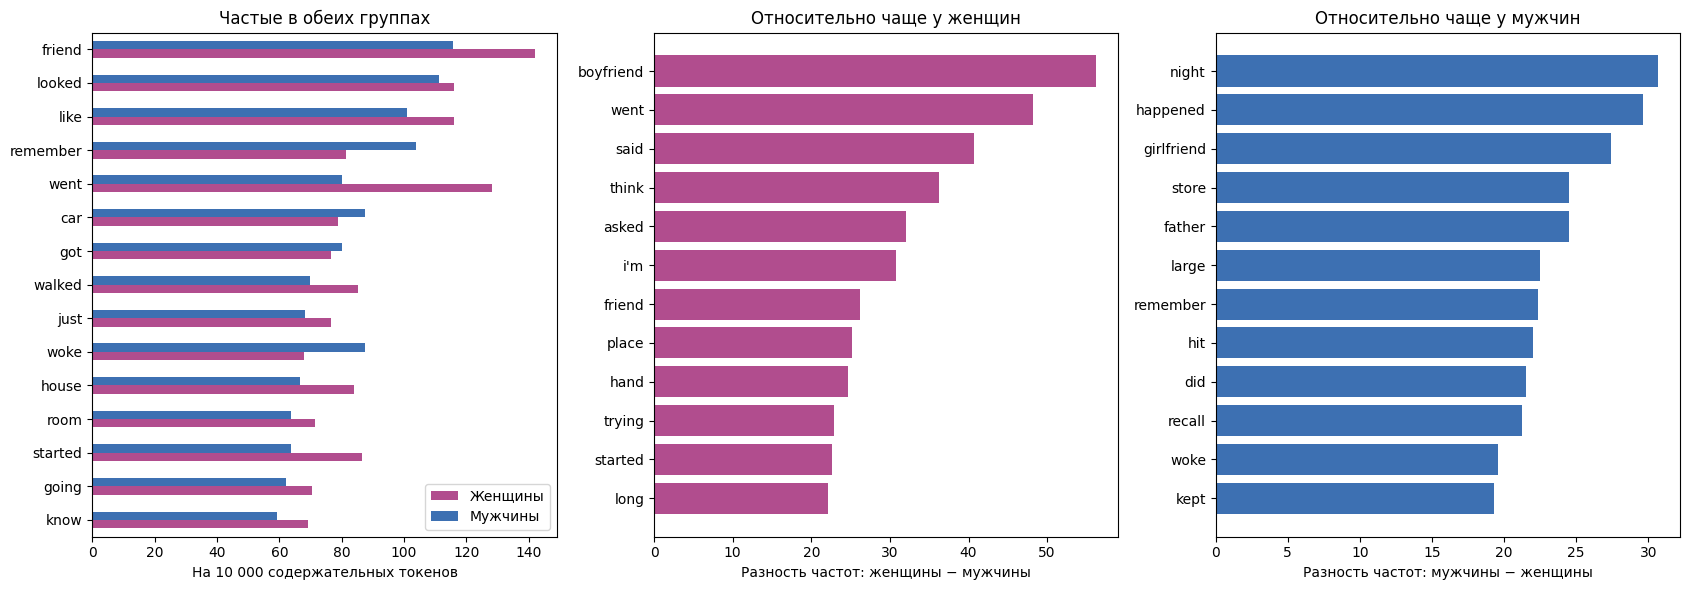

**Вывод:** часто встречаются слова о друзьях, движении, доме и воспоминании. Различительные слова — кандидаты для проверки на других выборках: отдельный длинный рассказ тоже может влиять на частоту. Показанная разница не доказывает различий между полами вообще.

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
common.set_index('word')[['female', 'male']].iloc[::-1].plot.barh(
    ax=axes[0], color=['#b14d8e', '#3d70b2'])
axes[0].legend(['Женщины', 'Мужчины'])
axes[0].set(title='Частые в обеих группах', xlabel='На 10 000 содержательных токенов', ylabel='')
axes[1].barh(female_words['word'].iloc[::-1], female_words['difference'].iloc[::-1], color='#b14d8e')
axes[1].set(title='Относительно чаще у женщин', xlabel='Разность частот: женщины − мужчины')
axes[2].barh(male_words['word'].iloc[::-1], -male_words['difference'].iloc[::-1], color='#3d70b2')
axes[2].set(title='Относительно чаще у мужчин', xlabel='Разность частот: мужчины − женщины')
fig.tight_layout()
fig.savefig(FIGURES / '05_words_by_gender.png', dpi=160, bbox_inches='tight')
plt.show()
display(Markdown('**Вывод:** часто встречаются слова о друзьях, движении, доме '
                 'и воспоминании. Различительные слова — кандидаты для проверки '
                 'на других выборках: отдельный длинный рассказ тоже может влиять '
                 'на частоту. Показанная разница не доказывает различий между полами вообще.'))

## Ограничения

Словарные оценки не разбирают сюжет. NMF реагирует на имена. Несколько записей одного автора зависимы. Возраст, эпоха и стиль меняются вместе.

Методы: [VADER](https://github.com/cjhutto/vaderSentiment), [NRCLex](https://pypi.org/project/NRCLex/), [NMF](https://scikit-learn.org/stable/modules/decomposition.html#nmf). Domhoff & Schneider (2008), [Studying dream content using the archive and search engine on DreamBank.net](https://doi.org/10.1016/j.concog.2008.06.010).

## 11. Дополнительный статистический анализ

В разделе считаются доли снов с признаком (как в опубликованных работах по архиву), проверяется,
не объясняется ли возрастной эффект длиной записи, и оценивается, что выборка вообще способна обнаружить.

Общие правила раздела:
- словарные показатели (NRC, регулярные выражения) — это **лексические маркеры**, а не события и не переживания;
- признак «в сне есть хотя бы одно слово» механически зависит от длины текста, поэтому длина всегда учитывается;
- сны одного дневника не независимы: где возможно, используются устойчивые ошибки, кластеры по блокам записей и bootstrap по блокам;
- при нескольких проверках применяется поправка Бенджамини–Хохберга (BH);
- функции вынесены в модуль `dreampoly_extended.py`, ячейки только вызывают их.

In [15]:
# Подключаем модуль с функциями раздела 11 и готовим папки результатов
import sys
import importlib

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import dreampoly_extended as ext
importlib.reload(ext)

import seaborn as sns
from IPython.display import display, Markdown

EXT_RESULTS = RESULTS / 'extended'
EXT_FIGURES = FIGURES / 'extended'
EXT_RESULTS.mkdir(parents=True, exist_ok=True)
EXT_FIGURES.mkdir(parents=True, exist_ok=True)

SEED = ext.RANDOM_SEED

### 11.1. Автоматическое выявление лексических маркеров агрессии

Считается доля снов, в которых найден хотя бы один лексический маркер агрессии, и частота маркеров на 1000 токенов. Используются два словаря: **широкий** (исходный список) и **строгий** (без «a bit», без «a crush», «shot» только в контексте выстрела). Совпадение слова не подтверждает эпизод физической агрессии.

Для проверки словаря выводится выборка контекстов (KWIC). Сравнение мужских и женских серий даёт разность долей с доверительным интервалом, h Коэна, критерий Фишера и поправку на длину текста.

In [16]:
# Выбираем серии и английские сновидения
AGGRESSION_SERIES = [
    'norms-f', 'norms-m',
    'college-f', 'college-m',
    'miami-home', 'miami-lab'
]

aggression_data = dreams.loc[
    dreams['series_id'].isin(AGGRESSION_SERIES)
    & dreams['language'].eq('en')
].copy()

assert aggression_data['dream_id'].is_unique, 'Обнаружены повторяющиеся dream_id'

# Число токенов считаем той же функцией tokens(), что и в features()
aggression_data['token_count'] = aggression_data['text'].apply(lambda t: len(tokens(t)))

# Маркеры по широкому и строгому словарям
aggression_data, marker_counts_broad = ext.add_marker_columns(
    aggression_data, ext.AGGRESSION_PATTERNS_BROAD, 'aggr_broad'
)
aggression_data, marker_counts_strict = ext.add_marker_columns(
    aggression_data, ext.AGGRESSION_PATTERNS_STRICT, 'aggr_strict'
)

print('Английских снов в анализе:', len(aggression_data))
print('Со словарём широким:', int(aggression_data['aggr_broad_present'].sum()))
print('Со словарём строгим:', int(aggression_data['aggr_strict_present'].sum()))

aggression_data.to_csv(
    EXT_RESULTS / 'aggression_lexical_markers_by_dream.csv',
    index=False, encoding='utf-8-sig'
)

Английских снов в анализе: 1745
Со словарём широким: 421
Со словарём строгим: 345


In [17]:
# Сводка по сериям для двух словарей
summary_broad = ext.summarize_by_series(
    aggression_data, 'aggr_broad_present', 'aggr_broad_count'
).assign(dictionary='broad')

summary_strict = ext.summarize_by_series(
    aggression_data, 'aggr_strict_present', 'aggr_strict_count'
).assign(dictionary='strict')

aggression_summary = pd.concat([summary_broad, summary_strict], ignore_index=True)
display(aggression_summary.round(4))

aggression_summary.to_csv(
    EXT_RESULTS / 'aggression_lexical_markers_by_series.csv',
    index=False, encoding='utf-8-sig'
)

# Частота отдельных маркеров (широкий словарь)
marker_frequency = (
    marker_counts_broad.sum().sort_values(ascending=False)
    .rename('occurrences').rename_axis('marker').reset_index()
)
display(marker_frequency)

,series_id,n_dreams,dreams_with_marker,prevalence,ci_low,ci_high,mean_tokens,markers_per_1000,dictionary
0,miami-lab,274,77,0.2810,0.2311,0.3370,353.0949,1.7158,broad
1,miami-home,171,48,0.2807,0.2187,0.3523,242.5789,2.7724,broad
2,norms-m,491,128,0.2607,0.2238,0.3013,118.6273,3.8801,broad
3,college-m,160,41,0.2562,0.1949,0.3291,115.6375,4.2158,broad
4,college-f,159,38,0.2390,0.1794,0.3109,139.5094,2.8401,broad
5,norms-f,490,89,0.1816,0.1500,0.2182,129.9143,2.0736,broad
6,miami-home,171,40,0.2339,0.1767,0.3028,242.5789,2.3143,strict
7,college-m,160,36,0.2250,0.1672,0.2957,115.6375,3.6212,strict
8,norms-m,491,107,0.2179,0.1837,0.2566,118.6273,3.2105,strict
9,miami-lab,274,54,0.1971,0.1543,0.2482,353.0949,1.2610,strict


,marker,occurrences
0,shoot,171
1,hit,121
2,bite,95
3,fight,89
4,kill,87
5,beat,39
6,hurt,37
7,attack,25
8,kick,16
9,murder,14


In [19]:
# Проверка точности словаря: вклад неоднозначных форм и выборка контекстов
lowered = aggression_data['text'].str.lower()

n_bit = int(lowered.str.count(r'\bbit\b').sum())
n_a_bit = int(lowered.str.count(r'\ba bit\b').sum())
n_shot = int(lowered.str.count(r'\bshot\b').sum())
n_shot_ctx = int(lowered.str.count(
    r'\b(?:was|were|got|get|gets|been|be|is|am|he|she|they|i|we|someone|him|her|me|them|us)\s+shot\b'
).sum())

print(f"'bit': всего {n_bit}, из них в сочетании 'a bit': {n_a_bit}")
print(f"'shot': всего {n_shot}, из них в контексте выстрела в кого-то: {n_shot_ctx}")

# Небольшой аудит: по 20 случайных контекстов на маркер.
# Столбец is_aggression_context можно заполнить 1/0 только для оценки точности словаря
kwic_audit = ext.kwic_sample(
    aggression_data, ext.AGGRESSION_PATTERNS_BROAD, n_per_marker=20, seed=SEED
)
kwic_audit.to_csv(
    EXT_RESULTS / 'aggression_kwic_audit.csv', index=False, encoding='utf-8-sig'
)
display(kwic_audit.groupby('marker').head(2).reset_index(drop=True))

'bit': всего 83, из них в сочетании 'a bit': 43
'shot': всего 90, из них в контексте выстрела в кого-то: 28


,marker,matched,dream_id,series_id,context,is_aggression_context
0,attack,attack,miami-lab:Phoenix-M-17,miami-lab,ame somehow overcome by something -- some unkn...,
1,attack,attack,norms-m:0217,norms-m,o a bear and was alive. The bear was preparing...,
2,kill,kill,norms-m:0030,norms-m,er was a fiendish sort of person who was going...,
3,kill,kill,norms-m:0030,norms-m,as going to kill me. I wasn't clear why he did...,
4,murder,murdered,miami-home:Phoenix-H-7,miami-home,"n that, but in this earlier part someone had b...",
5,murder,murders,miami-home:Phoenix-H-7,miami-home,e very famous for his ability to solve crimes ...,
6,fight,fighting,miami-lab:Erik-S-11,miami-lab,"only one ship. I saw a number of people, all ...",
7,fight,fight,miami-home:Ed-H-16,miami-home,ose in the cycle. The crowd was gathered aroun...,
8,beat,beat,miami-home:Sam-H-8,miami-home,nd I beat him. Then another wanted to fight an...,
9,beat,beat,norms-f:0423,norms-f,". No one could, but then on my last try I fina...",


In [20]:
# Сравнение мужских и женских серий: разность долей и поправка на длину
SEX_COMPARISONS = [('norms-m', 'norms-f'), ('college-m', 'college-f')]

sex_rows = []
for dictionary, prefix in [('broad', 'aggr_broad'), ('strict', 'aggr_strict')]:
    for series_a, series_b in SEX_COMPARISONS:
        row = ext.compare_two_series(
            aggression_data, series_a, series_b,
            f'{prefix}_present', f'{prefix}_count'
        )
        row['dictionary'] = dictionary
        sex_rows.append(row)

aggression_sex_tests = pd.DataFrame(sex_rows)

# Поправка BH внутри каждого словаря
for column in ['fisher_p', 'adj_or_p', 'rr_p']:
    aggression_sex_tests[column + '_bh'] = (
        aggression_sex_tests.groupby('dictionary')[column].transform(ext.adjust_pvalues)
    )

display(aggression_sex_tests[[
    'dictionary', 'series_a', 'series_b', 'p_1', 'p_2', 'diff_1_minus_2',
    'diff_ci_low', 'diff_ci_high', 'cohens_h', 'fisher_p', 'fisher_p_bh',
    'adj_or_a_vs_b', 'adj_or_ci_low', 'adj_or_ci_high', 'adj_or_p_bh',
    'rate_ratio_a_vs_b', 'rr_ci_low', 'rr_ci_high', 'rr_p_bh'
]].round(4))

aggression_sex_tests.to_csv(
    EXT_RESULTS / 'aggression_sex_comparisons.csv', index=False, encoding='utf-8-sig'
)

,dictionary,series_a,series_b,p_1,p_2,diff_1_minus_2,diff_ci_low,diff_ci_high,cohens_h,fisher_p,fisher_p_bh,adj_or_a_vs_b,adj_or_ci_low,adj_or_ci_high,adj_or_p_bh,rate_ratio_a_vs_b,rr_ci_low,rr_ci_high,rr_p_bh
0,broad,norms-m,norms-f,0.2607,0.1816,0.0791,0.0271,0.1305,0.1912,0.0034,0.0068,1.7374,1.2721,2.3729,0.0010,1.8712,1.3791,2.5389,0.0001
1,broad,college-m,college-f,0.2562,0.2390,0.0173,-0.0773,0.1114,0.0400,0.7955,0.7955,1.3186,0.7763,2.2399,0.3062,1.4843,0.9184,2.3991,0.1069
2,strict,norms-m,norms-f,0.2179,0.1633,0.0547,0.0055,0.1036,0.1395,0.0344,0.0688,1.5374,1.1093,2.1308,0.0196,1.7619,1.2720,2.4404,0.0013
3,strict,college-m,college-f,0.2250,0.1761,0.0489,-0.0393,0.1363,0.1223,0.3280,0.3280,1.5508,0.8818,2.7273,0.1277,1.7850,1.0454,3.0481,0.0338


**Результат.** В нормативных сериях маркеры агрессии чаще встречаются у мужчин: 26,1% против 18,2% по широкому словарю (BH: p = 0,0068). По строгому словарю разница меньше — 21,8% против 16,3% (BH: p = 0,0688), хотя модель с поправкой на длину показывает различие (OR = 1,54; BH: p = 0,0196). В студенческих сериях разница долей заметно слабее и по критерию Фишера незначима после поправки BH.


### 11.2. Влияние длины сна на лексику гнева

Признак «в тексте есть слово категории anger» механически чаще встречается в длинных текстах, даже если частота на слово не меняется.
Поэтому вместо логистической регрессии по наличию используется пуассоновская модель числа слов anger с поправкой `offset = log(токенов)`.
Коэффициент при `log(token_count)` равен нулю, если частота на слово не зависит от длины.

Дополнительно:
- симуляция при постоянной частоте внутри возраста показывает, какой наклон логита даёт одна лишь механика подсчёта;
- возрасты сравниваются при одинаковой длине (фиксированные интервалы);
- устойчивые ошибки HC3 учитывают разную дисперсию, кластеры по блокам из 20 подряд идущих снов — грубо учитывают зависимость соседних записей.

Анализ описывает один дневник и не доказывает влияния возраста.

In [21]:
# Данные Izzy: тексты от 50 до 500 токенов
izzy_length = ext.prepare_length_data(
    izzy, emotion='anger', min_tokens=50, max_tokens=500, block_size=20
)

print('Снов в анализе:', len(izzy_length))
print('Доля снов со словами anger:', round(izzy_length['present'].mean(), 4))

display(
    izzy_length.groupby('age_group', observed=True).agg(
        n_dreams=('dream_id', 'count'),
        median_tokens=('token_count', 'median'),
        anger_prevalence=('present', 'mean'),
        anger_per_1000=('anger_count', lambda s: s.sum())
    ).assign(
        anger_per_1000=lambda t: t['anger_per_1000'] / izzy_length.groupby(
            'age_group', observed=True)['token_count'].sum() * 1000
    ).round(4)
)

Снов в анализе: 3091
Доля снов со словами anger: 0.627


,n_dreams,median_tokens,anger_prevalence,anger_per_1000
age_group,,,,
12,27,75.0,0.5556,9.8542
13,95,84.0,0.5789,11.8227
14,185,97.0,0.6000,10.1067
15,235,76.0,0.5064,8.8840
16,481,94.0,0.5281,8.3100
17,571,136.0,0.6340,9.1591
18–21,1170,165.0,0.6880,8.4056
22–25,327,178.0,0.6636,7.9343


In [22]:
# Пуассоновская модель частоты с offset = log(токенов)
# Базовая возрастная группа — самая многочисленная (18–21)
res_hc3 = ext.fit_rate_model(izzy_length, 'anger_count', age_ref='18–21')
res_cluster = ext.fit_rate_model(izzy_length, 'anger_count', age_ref='18–21', cluster='block')

table_hc3 = ext.rate_model_table(res_hc3)
table_cluster = ext.rate_model_table(res_cluster)

print('Отношение дисперсии к среднему (Pearson chi2 / df):',
      round(res_hc3.pearson_chi2 / res_hc3.df_resid, 3))

print('\nМодель с ошибками HC3:')
display(table_hc3.round(4))
print('Модель с кластерами по блокам:')
display(table_cluster.round(4))

# Совместная проверка возраста
for name, res in [('HC3', res_hc3), ('кластеры', res_cluster)]:
    stat, p_value, df_age = ext.wald_block_test(res, 'age_group')
    print(f'Критерий Вальда для возраста ({name}): chi2={stat:.2f}, df={df_age}, p={p_value:.4f}')

length_key = 'np.log(token_count)'
print('\nКоэффициент при log(token_count): HC3 = %.3f [%.3f; %.3f], кластеры = %.3f [%.3f; %.3f]' % (
    res_hc3.params[length_key], *res_hc3.conf_int().loc[length_key],
    res_cluster.params[length_key], *res_cluster.conf_int().loc[length_key]))

table_hc3.to_csv(EXT_RESULTS / 'izzy_anger_rate_model_hc3.csv', encoding='utf-8-sig')
table_cluster.to_csv(EXT_RESULTS / 'izzy_anger_rate_model_cluster.csv', encoding='utf-8-sig')

Отношение дисперсии к среднему (Pearson chi2 / df): 1.376

Модель с ошибками HC3:


,coef,rate_ratio,ci_low,ci_high,p_value
Intercept,-4.7928,0.0083,0.0059,0.0117,0.0000
"C(age_group, Treatment(reference='18–21'))[T.12]",0.1608,1.1744,0.7524,1.8332,0.4792
"C(age_group, Treatment(reference='18–21'))[T.13]",0.3430,1.4091,1.0765,1.8445,0.0125
"C(age_group, Treatment(reference='18–21'))[T.14]",0.1856,1.2040,1.0126,1.4315,0.0356
"C(age_group, Treatment(reference='18–21'))[T.15]",0.0574,1.0590,0.8945,1.2538,0.5055
"C(age_group, Treatment(reference='18–21'))[T.16]",-0.0102,0.9899,0.8763,1.1182,0.8698
"C(age_group, Treatment(reference='18–21'))[T.17]",0.0861,1.0899,0.9887,1.2015,0.0835
"C(age_group, Treatment(reference='18–21'))[T.22–25]",-0.0579,0.9437,0.8366,1.0646,0.3461
np.log(token_count),0.0026,1.0026,0.9404,1.0689,0.9371


Модель с кластерами по блокам:


,coef,rate_ratio,ci_low,ci_high,p_value
Intercept,-4.7928,0.0083,0.0058,0.0119,0.0000
"C(age_group, Treatment(reference='18–21'))[T.12]",0.1608,1.1744,0.9051,1.5239,0.2264
"C(age_group, Treatment(reference='18–21'))[T.13]",0.3430,1.4091,1.0520,1.8875,0.0215
"C(age_group, Treatment(reference='18–21'))[T.14]",0.1856,1.2040,0.9288,1.5607,0.1609
"C(age_group, Treatment(reference='18–21'))[T.15]",0.0574,1.0590,0.8724,1.2856,0.5620
"C(age_group, Treatment(reference='18–21'))[T.16]",-0.0102,0.9899,0.8844,1.1079,0.8592
"C(age_group, Treatment(reference='18–21'))[T.17]",0.0861,1.0899,0.9956,1.1931,0.0623
"C(age_group, Treatment(reference='18–21'))[T.22–25]",-0.0579,0.9437,0.8382,1.0626,0.3384
np.log(token_count),0.0026,1.0026,0.9391,1.0704,0.9384


Критерий Вальда для возраста (HC3): chi2=15.05, df=7, p=0.0353
Критерий Вальда для возраста (кластеры): chi2=15.11, df=7, p=0.0346

Коэффициент при log(token_count): HC3 = 0.003 [-0.061; 0.067], кластеры = 0.003 [-0.063; 0.068]


Наклон логита по log(длины) в данных: 1.506
При постоянной частоте внутри возраста: среднее 1.746, 95% интервал [1.600; 1.905]


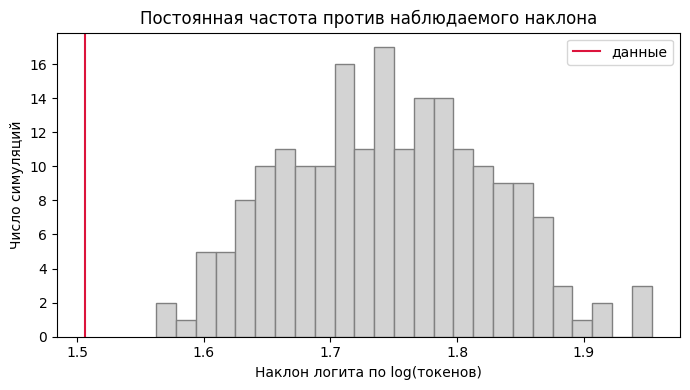

In [23]:
# Контроль «механики»: какой наклон логита по длине даёт постоянная частота
observed_slope, null_slopes = ext.simulate_null_logit_slope(
    izzy_length, 'anger_count', n_sim=200, seed=SEED
)

print('Наклон логита по log(длины) в данных: %.3f' % observed_slope)
print('При постоянной частоте внутри возраста: среднее %.3f, 95%% интервал [%.3f; %.3f]' % (
    null_slopes.mean(), *np.quantile(null_slopes, [0.025, 0.975])))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(null_slopes, bins=25, color='lightgray', edgecolor='gray')
ax.axvline(observed_slope, color='crimson', label='данные')
ax.set(xlabel='Наклон логита по log(токенов)', ylabel='Число симуляций',
       title='Постоянная частота против наблюдаемого наклона')
ax.legend()
fig.tight_layout()
fig.savefig(EXT_FIGURES / 'izzy_length_null_slope.png', dpi=150)
plt.show()

,age_group,length_bin,n_dreams,prevalence,prev_ci_low,prev_ci_high,rate_per_1000
0,12,50–99,19,0.5263,0.3171,0.7267,7.9745
1,12,100–199,7,0.5714,0.2505,0.8418,13.8889
2,12,200–500,1,1.0000,0.2065,1.0000,7.1599
3,13,50–99,65,0.5692,0.4483,0.6824,12.6224
4,13,100–199,26,0.5769,0.3895,0.7446,10.5453
5,13,200–500,4,0.7500,0.3006,0.9544,12.2850
6,14,50–99,94,0.5106,0.4112,0.6093,11.4926
7,14,100–199,73,0.6438,0.5293,0.7440,9.6223
8,14,200–500,18,0.8889,0.6720,0.9690,9.1556
9,15,50–99,161,0.4410,0.3666,0.5182,9.5621


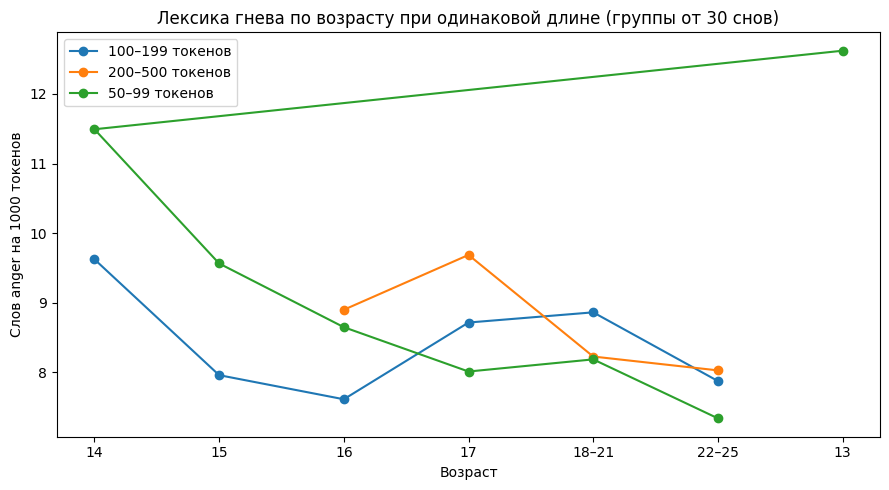

In [24]:
# Возрасты при одинаковой длине: фиксированные интервалы
length_bins = ext.length_bin_table(izzy_length, 'anger_count', edges=(50, 100, 200, 501))
display(length_bins.round(4))

length_bins.to_csv(EXT_RESULTS / 'izzy_anger_by_age_and_length_bin.csv',
                   index=False, encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(9, 5))
for lbin, g in length_bins.groupby('length_bin'):
    g = g[g['n_dreams'] >= 30]
    ax.plot(g['age_group'], g['rate_per_1000'], marker='o', label=f'{lbin} токенов')
ax.set(xlabel='Возраст', ylabel='Слов anger на 1000 токенов',
       title='Лексика гнева по возрасту при одинаковой длине (группы от 30 снов)')
ax.legend()
fig.tight_layout()
fig.savefig(EXT_FIGURES / 'izzy_anger_by_age_length_bins.png', dpi=150)
plt.show()

In [25]:
# Краткая сводка чисел для вывода
display(Markdown(
    f"**Числа для вывода.** Коэффициент при log(токенов) в модели частоты равен "
    f"{res_hc3.params[length_key]:.2f} (95% ДИ {res_hc3.conf_int().loc[length_key, 0]:.2f}"
    f"…{res_hc3.conf_int().loc[length_key, 1]:.2f}): значение 0 означало бы, что частота на слово "
    f"не зависит от длины. Наклон логита в данных — {observed_slope:.2f}, при постоянной частоте — "
    f"в среднем {null_slopes.mean():.2f}. Критерий Вальда для возраста: p = "
    f"{ext.wald_block_test(res_hc3, 'age_group')[1]:.3f}. "
    "Результат относится к одному дневнику."
))

**Числа для вывода.** Коэффициент при log(токенов) в модели частоты равен 0.00 (95% ДИ -0.06…0.07): значение 0 означало бы, что частота на слово не зависит от длины. Наклон логита в данных — 1.51, при постоянной частоте — в среднем 1.75. Критерий Вальда для возраста: p = 0.035. Результат относится к одному дневнику.

**Результат.** В 3 091 записи Izzy слова категории *anger* встречаются хотя бы раз в 62,7% снов. Доля таких записей выше в старших возрастных группах, но частота слов на 1 000 токенов не демонстрирует такого же роста: дополнительный коэффициент длины в модели близок к нулю (p = 0,938). При этом общий эффект возрастной группы в модели сохраняется (критерий Вальда, p = 0,0346).


### 11.3. Устойчивость показателей внутри возрастных папок Izzy

Каждая возрастная папка делится пополам по номеру сна. Для каждой группы и метрики сравниваются две половины:
разность средних, bootstrap-интервал по блокам, дельта Клиффа, критерий Манна–Уитни и поправка BH по всем сочетаниям группа×метрика.
Ранговая корреляция профилей по восьми возрастам не используется: она измеряет повторяемость возрастного тренда,
а у показателей без возрастного тренда (например, joy, MATTR) даёт случайные значения.

In [26]:
# Подготовка данных: сны от 50 токенов (как в разделе 11.2), порядок по номеру сна
izzy_stability = izzy.copy()
izzy_stability['dream_number'] = pd.to_numeric(
    izzy_stability['dream_number_raw'], errors='coerce'
)
izzy_stability = izzy_stability.dropna(subset=['dream_number', 'age_group'])
izzy_stability = izzy_stability[izzy_stability['token_count'] >= 50].copy()

STABILITY_METRICS = ['anger', 'fear', 'sadness', 'joy', 'token_count', 'mattr_50']

half_table = ext.compare_halves_by_group(
    izzy_stability, 'age_group', STABILITY_METRICS, order_col='dream_number',
    min_n=20, seed=SEED
)
half_summary = ext.summarize_half_differences(half_table)

display(half_table.round(4))
display(half_summary.round(4))

half_table.to_csv(EXT_RESULTS / 'izzy_halves_by_age.csv', index=False, encoding='utf-8-sig')
half_summary.to_csv(EXT_RESULTS / 'izzy_halves_summary.csv', index=False, encoding='utf-8-sig')

,group,metric,n_first,n_second,mean_first,mean_second,diff,boot_ci_low,boot_ci_high,cliffs_delta,p_value,p_adjusted_bh
0,13,anger,47,48,9.8956,14.0794,4.1838,-1.4159,9.5890,-0.0922,0.4232,0.8093
1,13,fear,47,48,15.9233,17.3628,1.4396,-2.1621,4.9442,0.0199,0.8686,0.9973
2,13,sadness,47,48,15.1708,16.0563,0.8854,-3.6987,4.3759,-0.0102,0.9341,0.9973
3,13,joy,47,48,12.4919,12.7125,0.2206,-6.8414,6.5918,0.0013,0.9939,0.9973
4,13,token_count,47,48,103.9574,88.5208,-15.4366,-33.0200,5.1191,0.1631,0.1719,0.5353
5,13,mattr_50,47,48,0.7478,0.7448,-0.0030,-0.0216,0.0160,0.0239,0.8436,0.9973
6,14,anger,92,93,9.6528,11.5559,1.9032,-2.5862,5.6625,-0.0732,0.3751,0.7877
7,14,fear,92,93,12.7898,15.5209,2.7310,-0.8214,6.1152,-0.0614,0.4624,0.8093
8,14,sadness,92,93,12.8177,14.6480,1.8303,-3.1147,6.4211,-0.1576,0.0601,0.4409
9,14,joy,92,93,11.2815,9.7151,-1.5663,-4.2533,1.4239,0.0967,0.2447,0.6045


,metric,n_groups,share_increased,n_significant_bh,median_abs_cliffs_delta
0,anger,7,0.4286,0,0.0240
1,fear,7,0.7143,0,0.0260
2,sadness,7,0.7143,0,0.0127
3,joy,7,0.7143,0,0.0441
4,token_count,7,0.4286,1,0.1004
5,mattr_50,7,0.2857,0,0.0598


**Результат.** После поправки BH в семи возрастных группах не выявлено значимых различий между половинами по четырём эмоциональным показателям и MATTR-50. Значимое изменение обнаружено только для длины записи в одной группе. В целом лексический и эмоциональный профиль внутри возрастных периодов изменяется слабее, чем объём текста.


### 11.4. Miami Home и Miami Lab

Сравниваются доли снов с лексическими маркерами агрессии в двух условиях.
В данных нет идентификатора человека, поэтому парность наблюдений проверить и учесть нельзя: ряды считаются независимыми.
Публикации по этим записям используют ручное кодирование физической агрессии, поэтому результат по словарю не является повторением их оценки.
Приводятся разность долей с интервалом, h Коэна, критерий Фишера, а также поправка на длину текста.

In [27]:
# Проверяем метаданные серий
display(series_df.loc[
    series_df['series_id'].isin(['miami-home', 'miami-lab']),
    ['series_id', 'series_title', 'dreamer_sex_raw', 'series_years_raw',
     'reported_count', 'parsed_count']
])

miami_rows = []
for dictionary, prefix in [('broad', 'aggr_broad'), ('strict', 'aggr_strict')]:
    row = ext.compare_two_series(
        aggression_data, 'miami-lab', 'miami-home',
        f'{prefix}_present', f'{prefix}_count'
    )
    row['dictionary'] = dictionary
    miami_rows.append(row)

miami_tests = pd.DataFrame(miami_rows)
miami_tests['fisher_p_bh'] = ext.adjust_pvalues(miami_tests['fisher_p'])

display(miami_tests[[
    'dictionary', 'n_a', 'n_b', 'mean_tokens_a', 'mean_tokens_b',
    'p_1', 'p_2', 'diff_1_minus_2', 'diff_ci_low', 'diff_ci_high',
    'cohens_h', 'fisher_p', 'adj_or_a_vs_b', 'adj_or_ci_low', 'adj_or_ci_high',
    'adj_or_p', 'rate_ratio_a_vs_b', 'rr_ci_low', 'rr_ci_high', 'rr_p'
]].round(4))

miami_tests.to_csv(EXT_RESULTS / 'miami_lexical_aggression_tests.csv',
                   index=False, encoding='utf-8-sig')

,series_id,series_title,dreamer_sex_raw,series_years_raw,reported_count,parsed_count
63,miami-home,Miami Home-Lab: Home,male,1963-1965,171,171
64,miami-lab,Miami Home-Lab: Lab,male,1963-1965,274,274


,dictionary,n_a,n_b,mean_tokens_a,mean_tokens_b,p_1,p_2,diff_1_minus_2,diff_ci_low,diff_ci_high,cohens_h,fisher_p,adj_or_a_vs_b,adj_or_ci_low,adj_or_ci_high,adj_or_p,rate_ratio_a_vs_b,rr_ci_low,rr_ci_high,rr_p
0,broad,274,171,353.0949,242.5789,0.2810,0.2807,0.0003,-0.0870,0.0838,0.0007,1.0000,0.5849,0.3579,0.9558,0.0323,0.6189,0.3970,0.9648,0.0342
1,strict,274,171,353.0949,242.5789,0.1971,0.2339,-0.0368,-0.1179,0.0399,-0.0897,0.4035,0.5664,0.3434,0.9345,0.0261,0.5449,0.3184,0.9325,0.0268


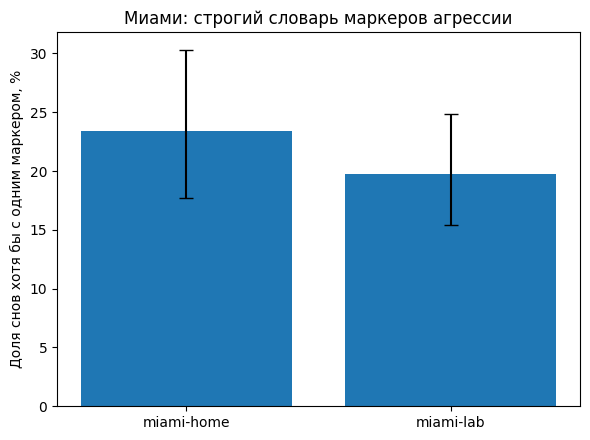

In [28]:
# Доли снов с маркерами (строгий словарь) и интервалы Уилсона
plot_data = summary_strict[summary_strict['series_id'].isin(['miami-home', 'miami-lab'])] \
    .set_index('series_id').loc[['miami-home', 'miami-lab']]

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.bar(plot_data.index, plot_data['prevalence'] * 100,
       yerr=[(plot_data['prevalence'] - plot_data['ci_low']) * 100,
             (plot_data['ci_high'] - plot_data['prevalence']) * 100],
       capsize=5)
ax.set(ylabel='Доля снов хотя бы с одним маркером, %',
       title='Миами: строгий словарь маркеров агрессии')
fig.tight_layout()
fig.savefig(EXT_FIGURES / 'miami_lexical_aggression_prevalence.png', dpi=150)
plt.show()

**Результат.** По широкому словарю доля снов с маркерами почти одинакова дома и в лаборатории (28,07% и 28,10%). По строгому словарю дома она выше (23,39% против 19,71%), но обычное сравнение долей не даёт значимого различия (p = 0,4035). После учёта длины записи модель показывает меньшие шансы появления маркеров в лаборатории (OR = 0,57; p = 0,0261).


### 11.5. Совместная встречаемость восьми категорий NRC

Категории NRC настолько широкие, что в серии norms 60–92% снов содержат слова каждой категории.
При таких долях lift почти равен 1 по построению, поэтому для каждой пары приводится максимально возможный lift.
Дополнительно:
- **отношение шансов Мантеля–Хэнзеля** по стратам длины текста (длинные сны содержат слова всех категорий);
- проверка на **словах, относящихся ровно к одной категории** (одно слово NRC часто записано сразу в несколько категорий);
- поправка BH по 28 парам внутри серии.

Результаты отражают совместную встречаемость лексики, а не одновременное переживание эмоций.

In [29]:
# Нормативные серии: признаки и бинарное наличие категорий NRC
norms_data = dreams[
    dreams['series_id'].isin(['norms-f', 'norms-m']) & dreams['language'].eq('en')
].copy()
assert norms_data['dream_id'].is_unique

norms_features = pd.DataFrame(
    [features(t) for t in norms_data['text']], index=norms_data.index
)
norms_data = pd.concat([norms_data, norms_features], axis=1)
norms_data = ext.add_emotion_presence(norms_data, EMOTIONS)
norms_data['length_stratum'] = ext.length_strata(norms_data['token_count'])

display(norms_data.groupby(['series_id', 'length_stratum'], observed=True).size().unstack())

length_stratum,<50,50–99,100–199,≥200
series_id,,,,
norms-f,2,136,313,39
norms-m,7,183,278,23


,series_id,emotion_a,emotion_b,joint_prevalence,lift,max_possible_lift,raw_odds_ratio,raw_p_adjusted_bh,mh_odds_ratio,mh_ci_low,mh_ci_high,mh_p_adjusted_bh
0,norms-f,anger,fear,0.5061,1.2338,1.4627,6.7546,0.0000,6.3155,4.1206,9.6795,0.0000
4,norms-f,anger,sadness,0.5408,1.1715,1.2997,6.8534,0.0000,6.4704,3.9965,10.4757,0.0000
5,norms-f,anger,disgust,0.4653,1.2418,1.6013,5.2261,0.0000,4.7895,3.2013,7.1657,0.0000
10,norms-f,fear,sadness,0.5939,1.1290,1.2997,5.3063,0.0000,4.9939,3.1576,7.8983,0.0000
21,norms-f,trust,joy,0.8082,1.0494,1.0865,12.8571,0.0000,11.0608,5.2849,23.1493,0.0000
17,norms-f,anticipation,joy,0.7755,1.0537,1.1369,7.2026,0.0000,6.5354,3.5537,12.0186,0.0000
14,norms-f,anticipation,surprise,0.6592,1.0675,1.1369,5.4118,0.0000,4.9829,2.7895,8.9010,0.0000
13,norms-f,anticipation,trust,0.8347,1.0310,1.0865,7.5249,0.0000,6.6363,3.1727,13.8808,0.0000
25,norms-f,sadness,disgust,0.5347,1.1128,1.2997,3.5727,0.0000,3.1842,2.0401,4.9700,0.0000
24,norms-f,surprise,joy,0.6245,1.0631,1.1951,3.2520,0.0000,3.1093,1.8817,5.1379,0.0000


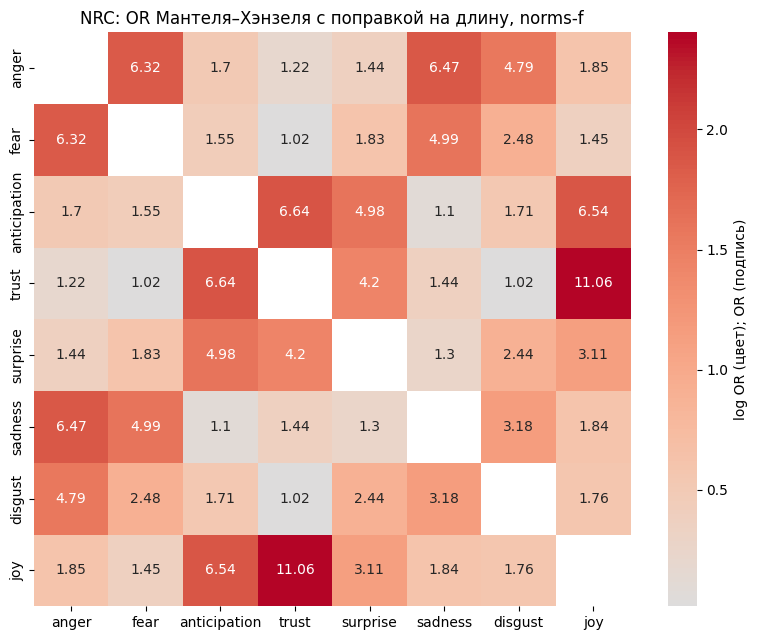

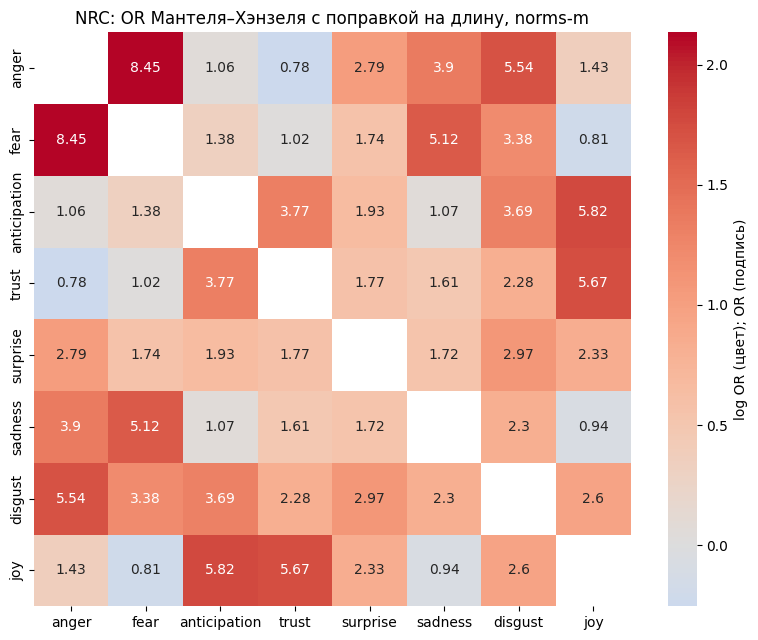

In [30]:
# Таблицы совместной встречаемости по сериям (все сны серии)
cooc_tables = {}
for series_id, group in norms_data.groupby('series_id'):
    table = ext.cooccurrence_table(group, EMOTIONS)
    table.insert(0, 'series_id', series_id)
    cooc_tables[series_id] = table

cooccurrence_df = pd.concat(cooc_tables.values(), ignore_index=True)

display(cooccurrence_df.sort_values(
    ['series_id', 'mh_p_adjusted_bh']
)[['series_id', 'emotion_a', 'emotion_b', 'joint_prevalence', 'lift',
   'max_possible_lift', 'raw_odds_ratio', 'raw_p_adjusted_bh',
   'mh_odds_ratio', 'mh_ci_low', 'mh_ci_high', 'mh_p_adjusted_bh']].round(4))

cooccurrence_df.to_csv(EXT_RESULTS / 'nrc_emotion_cooccurrence.csv',
                       index=False, encoding='utf-8-sig')

# Тепловые карты логарифма OR Мантеля–Хэнзеля
for series_id, table in cooc_tables.items():
    matrix = ext.odds_ratio_matrix(table, 'mh_odds_ratio', EMOTIONS)
    fig, ax = plt.subplots(figsize=(8, 6.5))
    sns.heatmap(np.log(matrix), annot=matrix.round(2), fmt='', cmap='coolwarm',
                center=0, ax=ax, cbar_kws={'label': 'log OR (цвет); OR (подпись)'})
    ax.set_title(f'NRC: OR Мантеля–Хэнзеля с поправкой на длину, {series_id}')
    fig.tight_layout()
    fig.savefig(EXT_FIGURES / f'nrc_mh_or_{series_id}.png', dpi=150)
    plt.show()

In [31]:
# Проверка на словах, относящихся ровно к одной категории NRC
try:
    nrc_lexicon = ext.get_nrc_lexicon(nrc)

    exclusive = pd.DataFrame(
        [ext.exclusive_emotion_counts(tokens(t), nrc_lexicon, EMOTIONS)
         for t in norms_data['text']],
        index=norms_data.index
    )
    exclusive_data = norms_data[['series_id', 'token_count', 'length_stratum']].copy()
    for emotion in EMOTIONS:
        exclusive_data[f'{emotion}_present'] = (exclusive[emotion] > 0).astype(int)

    exclusive_tables = []
    for series_id, group in exclusive_data.groupby('series_id'):
        table = ext.cooccurrence_table(group, EMOTIONS)
        table.insert(0, 'series_id', series_id)
        exclusive_tables.append(table)
    cooccurrence_exclusive = pd.concat(exclusive_tables, ignore_index=True)

    print('Распространённость категорий по «однозначным» словам:')
    display(exclusive_data.groupby('series_id')[[f'{e}_present' for e in EMOTIONS]].mean().round(3))

    display(cooccurrence_exclusive.sort_values(
        ['series_id', 'mh_p_adjusted_bh']
    )[['series_id', 'emotion_a', 'emotion_b', 'joint_prevalence', 'lift',
       'mh_odds_ratio', 'mh_p_adjusted_bh']].head(20).round(4))

    cooccurrence_exclusive.to_csv(EXT_RESULTS / 'nrc_emotion_cooccurrence_exclusive_words.csv',
                                  index=False, encoding='utf-8-sig')
except AttributeError as error:
    print('Пропускаем проверку по однозначным словам:', error)

Распространённость категорий по «однозначным» словам:


,anger_present,fear_present,anticipation_present,trust_present,surprise_present,sadness_present,disgust_present,joy_present
series_id,,,,,,,,
norms-f,0.155,0.220,0.559,0.629,0.282,0.435,0.239,0.253
norms-m,0.216,0.257,0.580,0.613,0.283,0.389,0.151,0.181


,series_id,emotion_a,emotion_b,joint_prevalence,lift,mh_odds_ratio,mh_p_adjusted_bh
8,norms-f,fear,trust,0.1245,0.8986,0.6271,0.2870
23,norms-f,surprise,disgust,0.0878,1.3050,1.6664,0.2870
24,norms-f,surprise,joy,0.0918,1.2886,1.6088,0.2870
25,norms-f,sadness,disgust,0.0878,0.8455,0.6110,0.2870
0,norms-f,anger,fear,0.0469,1.3731,1.5735,0.5812
5,norms-f,anger,disgust,0.0490,1.3225,1.4957,0.6862
2,norms-f,anger,trust,0.1082,1.1094,1.2838,0.8236
3,norms-f,anger,surprise,0.0531,1.2147,1.2975,0.8236
7,norms-f,fear,anticipation,0.1367,1.1094,1.2677,0.8236
10,norms-f,fear,sadness,0.1082,1.1289,1.2419,0.8236


**Результат.** По полному словарю NRC некоторые категории часто встречаются вместе: например, в `norms-f` сочетание *anger–fear* найдено в 50,6% снов (lift = 1,23). При использовании слов, относящихся ровно к одной категории, эта доля снижается до 4,7%; для данной пары скорректированная связь уже незначима (BH: p = 0,581). Следовательно, часть высокой совместной встречаемости объясняется пересечением категорий внутри словаря NRC.


### 11.6. Эмоциональный профиль дневника Barb Sanders

Ранговая корреляция восьми категорий NRC между двумя частями дневника всегда близка к 1:
порядок категорий (trust выше anticipation выше joy и т. д.) определяется размером словаря каждой категории и одинаков почти для любого английского текста.
Поэтому сравнение идёт по каждой категории отдельно: разность средних с bootstrap-интервалом по блокам, дельта Клиффа, критерий Манна–Уитни и поправка BH.

Сравниваются: (1) первая и вторая половины серии `b` (1960–1997); (2) серия `b` и серия `b2` (1997–2001).
Для контроля показана ранговая корреляция профиля `b` с профилем студенток `college-f`.

In [32]:
# Метаданные серий b и b2
display(series_df.loc[
    series_df['series_id'].isin(['b', 'b2']),
    ['series_id', 'series_title', 'dreamer_sex_raw', 'series_years_raw',
     'reported_count', 'parsed_count']
])

# Признаки для серий b и b2; сны от 50 токенов
b_data = dreams[dreams['series_id'].isin(['b', 'b2'])].copy()
b_data['dream_number'] = pd.to_numeric(b_data['dream_number_raw'], errors='coerce')
b_data = b_data.dropna(subset=['dream_number']).sort_values(['series_id', 'dream_number'])

b_features = pd.DataFrame([features(t) for t in b_data['text']], index=b_data.index)
b_data = pd.concat([b_data, b_features], axis=1)
b_data = b_data[b_data['token_count'] >= 50].copy()

B_METRICS = EMOTIONS + ['token_count']
b_only = b_data[b_data['series_id'] == 'b']
b2_only = b_data[b_data['series_id'] == 'b2']
print('Снов в b:', len(b_only), '; в b2:', len(b2_only))

,series_id,series_title,dreamer_sex_raw,series_years_raw,reported_count,parsed_count
3,b,Barb Sanders,female,1960-1997,3116,3114
5,b2,Barb Sanders #2,female,1997-2001,1138,1138


Снов в b: 2613 ; в b2: 1084


In [33]:
# (1) первая и вторая половины серии b
b_first, b_second = ext.split_halves(b_only, 'dream_number')
b_halves = ext.compare_emotion_profiles(
    b_first, b_second, B_METRICS, 'first_half', 'second_half', seed=SEED
)
print('Серия b: вторая половина минус первая')
display(b_halves.round(4))

# (2) серия b и серия b2
b_vs_b2 = ext.compare_emotion_profiles(
    b_only.sort_values('dream_number'), b2_only.sort_values('dream_number'),
    B_METRICS, 'b', 'b2', seed=SEED
)
print('b2 минус b')
display(b_vs_b2.round(4))

b_halves.to_csv(EXT_RESULTS / 'barb_sanders_halves.csv', index=False, encoding='utf-8-sig')
b_vs_b2.to_csv(EXT_RESULTS / 'barb_sanders_b_vs_b2.csv', index=False, encoding='utf-8-sig')

Серия b: вторая половина минус первая


,metric,mean_first_half,mean_second_half,diff_b_minus_a,boot_ci_low,boot_ci_high,cliffs_delta_a_vs_b,p_value,n_a,n_b,p_adjusted_bh
0,anger,12.4588,12.9792,0.5203,-0.5634,1.5107,-0.0412,0.0666,1306,1307,0.1199
1,fear,15.5762,15.9097,0.3335,-1.0990,1.7630,-0.0417,0.0640,1306,1307,0.1199
2,anticipation,23.7075,23.2639,-0.4436,-1.7513,0.8519,0.0049,0.8273,1306,1307,0.9202
3,trust,25.1411,24.9410,-0.2001,-1.5528,1.1829,-0.0183,0.4179,1306,1307,0.5373
4,surprise,12.5869,12.0683,-0.5186,-1.4691,0.4155,0.0023,0.9202,1306,1307,0.9202
5,sadness,17.1806,17.2834,0.1028,-1.0616,1.2436,-0.0227,0.3148,1306,1307,0.4721
6,disgust,9.5576,10.8835,1.3259,0.3787,2.2130,-0.0980,0.0000,1306,1307,0.0001
7,joy,22.2036,23.2410,1.0374,-0.5226,2.5791,-0.0510,0.0239,1306,1307,0.0716
8,token_count,183.3132,248.3122,64.9990,45.7921,85.4125,-0.2807,0.0000,1306,1307,0.0000


b2 минус b


,metric,mean_b,mean_b2,diff_b_minus_a,boot_ci_low,boot_ci_high,cliffs_delta_a_vs_b,p_value,n_a,n_b,p_adjusted_bh
0,anger,12.7191,12.8505,0.1314,-0.8749,1.0745,0.0225,0.2776,2613,1084,0.6245
1,fear,15.7430,15.4008,-0.3422,-1.4552,0.7556,0.0489,0.0186,2613,1084,0.1540
2,anticipation,23.4856,23.9517,0.4661,-0.7361,1.6444,-0.0078,0.7069,2613,1084,0.9546
3,trust,25.0410,25.3715,0.3305,-0.9215,1.5776,-0.0012,0.9546,2613,1084,0.9546
4,surprise,12.3275,11.6792,-0.6483,-1.3704,0.1067,0.0440,0.0342,2613,1084,0.1540
5,sadness,17.2320,17.5005,0.2686,-0.9786,1.5248,0.0031,0.8823,2613,1084,0.9546
6,disgust,10.2208,10.4650,0.2442,-0.7146,1.1761,-0.0065,0.7517,2613,1084,0.9546
7,joy,22.7225,22.8729,0.1504,-1.3728,1.5735,0.0268,0.1991,2613,1084,0.5974
8,token_count,215.8251,202.6089,-13.2162,-28.1704,2.1847,0.0120,0.5641,2613,1084,0.9546


Spearman b и b2:         1.000
Spearman b и college-f:  0.976


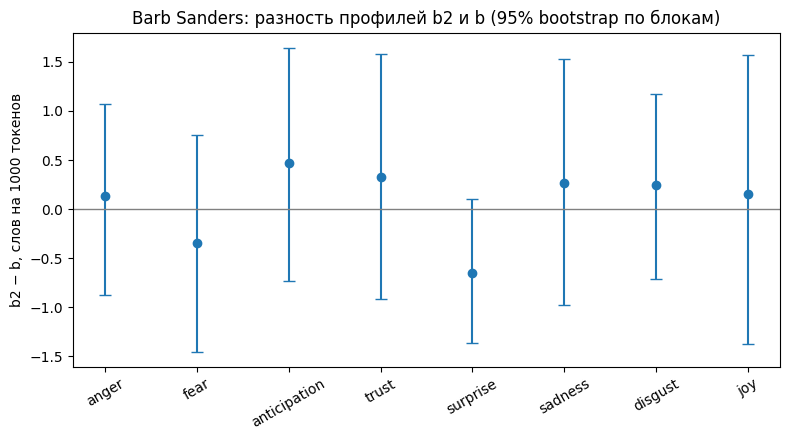

In [34]:
# Контрольное сравнение: ранговая корреляция профилей разных текстов
from scipy.stats import spearmanr

profile_b = b_only[EMOTIONS].mean()
profile_b2 = b2_only[EMOTIONS].mean()
profile_college_f = college.loc[college['group'] == 'Женщины', EMOTIONS].mean()

print('Spearman b и b2:         %.3f' % spearmanr(profile_b, profile_b2)[0])
print('Spearman b и college-f:  %.3f' % spearmanr(profile_b, profile_college_f)[0])

# Разности по категориям с bootstrap-интервалами
plot_b = b_vs_b2[b_vs_b2['metric'].isin(EMOTIONS)].set_index('metric').loc[EMOTIONS]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(range(len(EMOTIONS)), plot_b['diff_b_minus_a'],
            yerr=[plot_b['diff_b_minus_a'] - plot_b['boot_ci_low'],
                  plot_b['boot_ci_high'] - plot_b['diff_b_minus_a']],
            fmt='o', capsize=4)
ax.axhline(0, color='gray', linewidth=1)
ax.set_xticks(range(len(EMOTIONS)), EMOTIONS, rotation=30)
ax.set(ylabel='b2 − b, слов на 1000 токенов',
       title='Barb Sanders: разность профилей b2 и b (95% bootstrap по блокам)')
fig.tight_layout()
fig.savefig(EXT_FIGURES / 'barb_sanders_b2_minus_b.png', dpi=150)
plt.show()

**Результат.** Во второй половине серии `b` средняя длина записи выросла примерно на 65 токенов, а показатель *disgust* — на 1,33 слова на 1 000 токенов; оба изменения значимы после BH. Между сериями `b` и `b2` значимых различий по рассмотренным метрикам после BH не обнаружено. Ранговая корреляция профилей `b` и `b2` равна 1,000: порядок восьми эмоциональных категорий полностью совпадает.


### 11.7. Влияние имён собственных на тематическую модель

В исходной модели темы «Школа», «Семья и дом» и «Повторяющиеся имена» содержат имена знакомых автора дневника.
Здесь список имён строится автоматически: слова, которые почти всегда пишутся с заглавной буквы не в начале предложения.
Родственные слова (mom, dad, nana) исключены из списка, потому что они несут смысл темы.
**Список нужно просмотреть глазами**: в него могут попасть географические названия.

Базовая модель и модель без имён обучаются с одинаковыми параметрами TF-IDF и NMF, меняется только список стоп-слов.
Темы двух моделей сопоставляются по косинусной близости, а вес темы «школа» сравнивается по возрастам.

In [35]:
# Тексты в том же порядке, что и в разделе 8
izzy_topics = izzy.sort_values(['series_id', 'dream_number_raw']).reset_index(drop=True)
topic_texts = izzy_topics['text'].fillna('').tolist()

# Автоматический поиск кандидатов в имена
names_table = ext.find_person_names(topic_texts, min_count=5, min_ratio=0.9)
print('Найдено кандидатов в имена:', len(names_table))
display(names_table.head(60))

names_table.to_csv(EXT_RESULTS / 'izzy_name_candidates.csv', index=False, encoding='utf-8-sig')

Найдено кандидатов в имена: 615


,word,capital_mid_count,lower_count,capital_ratio
0,ezra,1235,0,1.000000
1,eugene,622,0,1.000000
2,calvin,351,0,1.000000
3,darren,231,0,1.000000
4,michael,144,0,1.000000
5,dmitri,138,0,1.000000
6,darius,122,0,1.000000
7,dawson,117,0,1.000000
8,evelyn,117,0,1.000000
9,samantha,111,0,1.000000


In [36]:
# Слова, которые НЕ нужно считать именами людей (бренды, игры, сериалы, места, нарицательные слова).
# Просмотрите таблицу names_table выше и дополните список
NOT_NAMES = {
    'facebook', 'runescape', 'asian', 'english', 'sims', 'warcraft', 'pokemon',
    'supernatural', 'technical', 'development', 'creek', 'smallville', 'firefly',
    'mcdonald', 'midvale', 'buffy', 'tigger'
}

PERSON_NAMES = set(names_table['word']) - NOT_NAMES

# Базовая модель (должна совпасть с разделом 8) и модель без имён
fit_base = ext.fit_nmf_topics(topic_texts, extra_stop_words=(), seed=SEED)
fit_no_names = ext.fit_nmf_topics(topic_texts, extra_stop_words=PERSON_NAMES, seed=SEED)

topics_compare = pd.DataFrame({
    'topic': range(1, 9),
    'base_terms': ext.topic_top_terms(fit_base),
    'no_names_terms': ext.topic_top_terms(fit_no_names),
})
display(topics_compare)

# Сопоставление тем двух моделей
topic_matching = ext.match_topics(fit_base, fit_no_names)
display(topic_matching.round(3))

topics_compare.to_csv(EXT_RESULTS / 'topics_base_vs_no_names.csv',
                      index=False, encoding='utf-8-sig')
topic_matching.to_csv(EXT_RESULTS / 'topics_matching.csv',
                      index=False, encoding='utf-8-sig')

,topic,base_terms,no_names_terms
0,1,"said, like, didn, asked, know, saying, just, t...","said, like, asked, didn, talking, know, saying..."
1,2,"calvin, school, dmitri, samantha, evelyn, elij...","remember, don remember, don, dream, properly, ..."
2,3,"remember, don remember, don, dream, properly, ...","school, class, teacher, ms, bench, mr, people,..."
3,4,"ezra, mom, dad, home, car, mom ezra, dad ezra,...","watching, movie, watching movie, guy, girl, tv..."
4,5,"watching, movie, watching movie, guy, tv, girl...","mom, car, shop, went, got, driving, drove, mom..."
5,6,"guy, people, got, place, thing, girl, went, ca...","people, guy, went, got, ran, door, thing, plac..."
6,7,"room, house, door, bed, went, came, outside, r...","dad, nana, home, room, going, poppa, went, dad..."
7,8,"eugene, darius, jeremiah, bradley, thinking, s...","playing, game, playing game, sims, world, warc..."


,topic_a,topic_b,cosine
0,1,1,0.989
1,2,3,0.962
2,3,2,0.996
3,4,5,0.763
4,5,4,0.986
5,6,6,0.892
6,7,7,0.304
7,8,8,0.122


,school_topic_base,school_topic_no_names
group,,
12,0.1574,0.2172
13,0.0982,0.1708
14,0.1703,0.1999
15,0.2620,0.1961
16,0.1099,0.1329
17,0.0864,0.1213
18–21,0.0384,0.0513
22–25,0.0219,0.0488


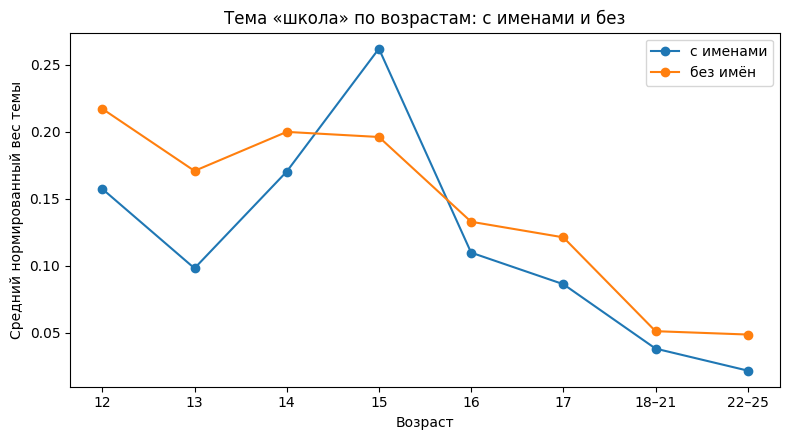

In [37]:
# Вес темы «школа» по возрастам в обеих моделях
school_base = ext.topic_index_by_term(fit_base, 'school')
school_no_names = ext.topic_index_by_term(fit_no_names, 'school')

shares_base = ext.topic_shares_by_group(fit_base, izzy_topics['age_group']).reindex(AGES)
shares_no_names = ext.topic_shares_by_group(fit_no_names, izzy_topics['age_group']).reindex(AGES)

school_by_age = pd.DataFrame({
    'school_topic_base': shares_base[f'topic_{school_base + 1}'],
    'school_topic_no_names': shares_no_names[f'topic_{school_no_names + 1}'],
})
display(school_by_age.round(4))
school_by_age.to_csv(EXT_RESULTS / 'school_topic_share_by_age.csv', encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(AGES, school_by_age['school_topic_base'], marker='o', label='с именами')
ax.plot(AGES, school_by_age['school_topic_no_names'], marker='o', label='без имён')
ax.set(xlabel='Возраст', ylabel='Средний нормированный вес темы',
       title='Тема «школа» по возрастам: с именами и без')
ax.legend()
fig.tight_layout()
fig.savefig(EXT_FIGURES / 'school_topic_with_without_names.png', dpi=150)
plt.show()

**Результат.** После удаления автоматически выделенных имён тема «школа» по-прежнему определяется словами *school*, *class*, *teacher* и остаётся сопоставимой с исходной темой (косинусная близость 0,962). Её средний нормированный вес снижается к старшим возрастам: с 0,217 в 12 лет до 0,049 в 22–25 лет. Таким образом, снижение школьной тематики сохраняется и в модели без имён.


### 11.8. Статистическая мощность и минимальная обнаружимая разность

Вместо одной кривой мощности для n = 160 считается **минимальная разность долей, которую выборка обнаруживает с мощностью 80%** (при α = 0,05),
для фактических объёмов серий и разных базовых частот. Если реальная разность меньше этого значения, отсутствие значимого различия означает лишь недостаток снов.

Сны одного человека зависимы, поэтому дополнительно показан эффект дизайна (deff): эффективный объём равен n / deff.
Значения deff 1,5 и 2,0 — условные сценарии, а не оценка по данным.
Для сопоставления с известными долями (13,9% и 26,5%) мощность проверяется моделированием критерия Фишера.

MDE в процентных пунктах (deff = 1):


base_rate,0.05,0.10,0.15,0.20,0.25
design,,,,,
college-f / college-m,8.9,11.2,12.7,13.8,14.6
miami-home / miami-lab,7.5,9.6,10.9,11.9,12.6
norms-f / norms-m,4.6,6.0,6.9,7.6,8.1


MDE в процентных пунктах при deff = 2:


base_rate,0.05,0.10,0.15,0.20,0.25
design,,,,,
college-f / college-m,13.7,16.8,18.7,20.1,21.0
miami-home / miami-lab,11.5,14.2,16.0,17.3,18.1
norms-f / norms-m,6.9,8.8,10.1,11.0,11.6


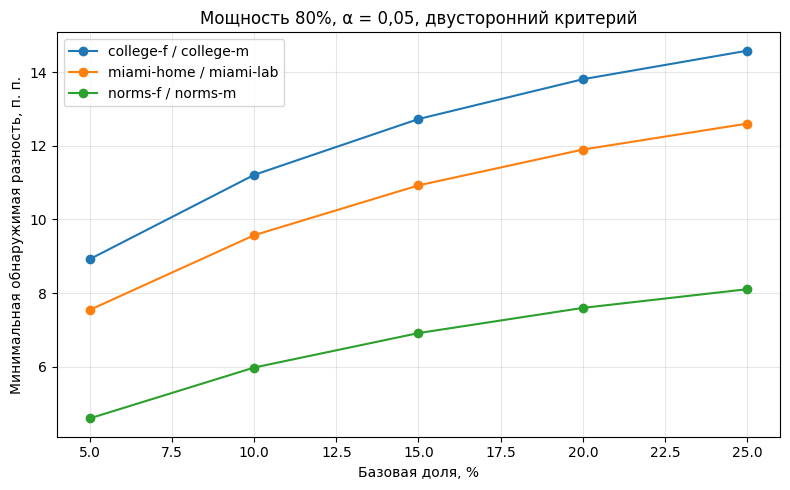

In [38]:
# Фактические объёмы выборок берём из данных
sizes = aggression_data['series_id'].value_counts()

DESIGNS = {
    'college-f / college-m': (int(sizes['college-f']), int(sizes['college-m'])),
    'norms-f / norms-m': (int(sizes['norms-f']), int(sizes['norms-m'])),
    'miami-home / miami-lab': (int(sizes['miami-home']), int(sizes['miami-lab'])),
}

BASE_RATES = [0.05, 0.10, 0.15, 0.20, 0.25]

mde_df = ext.mde_table(DESIGNS, BASE_RATES, power=0.8, alpha=0.05, deffs=(1.0, 1.5, 2.0))

print('MDE в процентных пунктах (deff = 1):')
display((mde_df[mde_df['deff'] == 1.0]
         .pivot(index='design', columns='base_rate', values='mde') * 100).round(1))

print('MDE в процентных пунктах при deff = 2:')
display((mde_df[mde_df['deff'] == 2.0]
         .pivot(index='design', columns='base_rate', values='mde') * 100).round(1))

mde_df.to_csv(EXT_RESULTS / 'minimum_detectable_difference.csv',
              index=False, encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(8, 5))
for design, g in mde_df[mde_df['deff'] == 1.0].groupby('design'):
    ax.plot(g['base_rate'] * 100, g['mde'] * 100, marker='o', label=design)
ax.set(xlabel='Базовая доля, %', ylabel='Минимальная обнаружимая разность, п. п.',
       title='Мощность 80%, α = 0,05, двусторонний критерий')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(EXT_FIGURES / 'minimum_detectable_difference.png', dpi=150)
plt.show()

In [39]:
# Мощность критерия Фишера для известных долей физической агрессии (13,9% и 26,5%)
power_rows = []
for design, (n1, n2) in DESIGNS.items():
    power_rows.append({
        'design': design, 'n1': n1, 'n2': n2,
        'power_fisher_13.9_vs_26.5': ext.simulate_fisher_power(
            n1, n2, 0.139, 0.265, n_sim=2000, seed=SEED)
    })
fisher_power = pd.DataFrame(power_rows)
display(fisher_power.round(3))
fisher_power.to_csv(EXT_RESULTS / 'fisher_power_known_rates.csv',
                    index=False, encoding='utf-8-sig')

,design,n1,n2,power_fisher_13.9_vs_26.5
0,college-f / college-m,159,160,0.764
1,norms-f / norms-m,490,491,0.998
2,miami-home / miami-lab,171,274,0.876


**Результат.** При базовой доле 15% и мощности 80% минимальная обнаружимая разница составляет 6,9 п.п. для `norms-f / norms-m` и 12,7 п.п. для `college-f / college-m`. Для разницы 13,9% против 26,5% моделирование критерия Фишера даёт мощность 99,8% на `norms`, 76,4% на `college` и 87,6% на `Miami`. Самые крупные нормативные серии позволяют обнаруживать более небольшие различия.


### Общие результаты раздела 11

В нормативных сериях мужские записи содержат больше лексических маркеров агрессии; в студенческих сериях различие выражено слабее. Для дневника Izzy присутствие эмоциональных слов зависит от длины текста, тогда как их частота на 1 000 токенов ведёт себя иначе. Профиль Barb Sanders сохраняет близкую структуру между периодами, а школьная тематика Izzy становится менее выраженной в старших возрастных группах. Анализ мощности показывает преимущество более крупных нормативных выборок.
